# Cvičenie II - Lineárne modely a predikcia časových radov

## Predikcia s ARIMA modelmi

Modely Arima predstavujú široko používanú skupinu modelov na analýzu a predikciu stacionárnych časových radov.

### Lag v autokorelácii
Lag vyjadruje o koľko časových krokov porovnávame aktuálnu hodnotu s hodnotou z minulosti.

Napríklad:
- **lag 1**: porovnávame ($Y{_t}$) s ($Y_{t-1}$)
- **lag 2**: porovnávame ($Y{_t}$) s ($Y_{t-2}$)
- **lag 12**: aktuálnu hodnotu porovnávame s hodnotou spred 12 období

S lagmi sa stretávame pri autokorelácii, pretože autokorelácia meria, ako silno súvisí časový rad so svojimi vlastnými minulými hodnotami pri rôznych lagoch.

To nám pomáha odhaliť napríklad:

- krátkodobú závislosť medzi susednými pozorovaniami,
- opakujúce sa sezónne vzory,
- či minulé hodnoty obsahujú informáciu užitočnú pre predikciu.

---

#### Rozdiel medzi ACF a PACF: Celková vs. priama závislosť

<div align="center">
<img src="images/acf_vs_pacf.png" alt="ACF vs PACF perspektíva" width="480"/>
</div>

## ARIMA model

ARIMA kombinuje tri zložky – autoregresiu, diferencovanie a moving-average zložku.

### AR(p) – Autoregresná zložka

Autoregresná zložka modeluje vzťah medzi aktuálnym pozorovaním a jeho vlastnými minulými hodnotami:

$$X_t = c + \phi_1 X_{t-1} + \phi_2 X_{t-2} + \dots + \phi_p X_{t-p} + \varepsilon_t$$


Parameter \(p\) určuje, koľko minulých hodnôt priamo vstupuje do modelu.

### I(d) – Integrovaná zložka

Parameter \(d\) vyjadruje, koľkokrát časový rad diferencujeme, aby sme získali približne stacionárny rad.

Ak prvá diferencia vytvorí stacionárny rad, potom \(d=1\).

### MA(q) – Moving-average

MA zložka modeluje vzťah medzi aktuálnym pozorovaním a minulými náhodnými šokmi:

$$X_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \theta_2 \varepsilon_{t-2} + \dots + \theta_q \varepsilon_{t-q}$$

Parameter \(q\) určuje počet minulých inovácií, ktoré vstupujú do modelu.

--------
## 1. Príprava dát

Total observations: 440
Training observations: 352 (80.0%)
Testing observations: 88 (20.0%)
Training period: 1980-01-01 to 2009-04-01
Testing period: 2009-05-01 to 2016-08-01


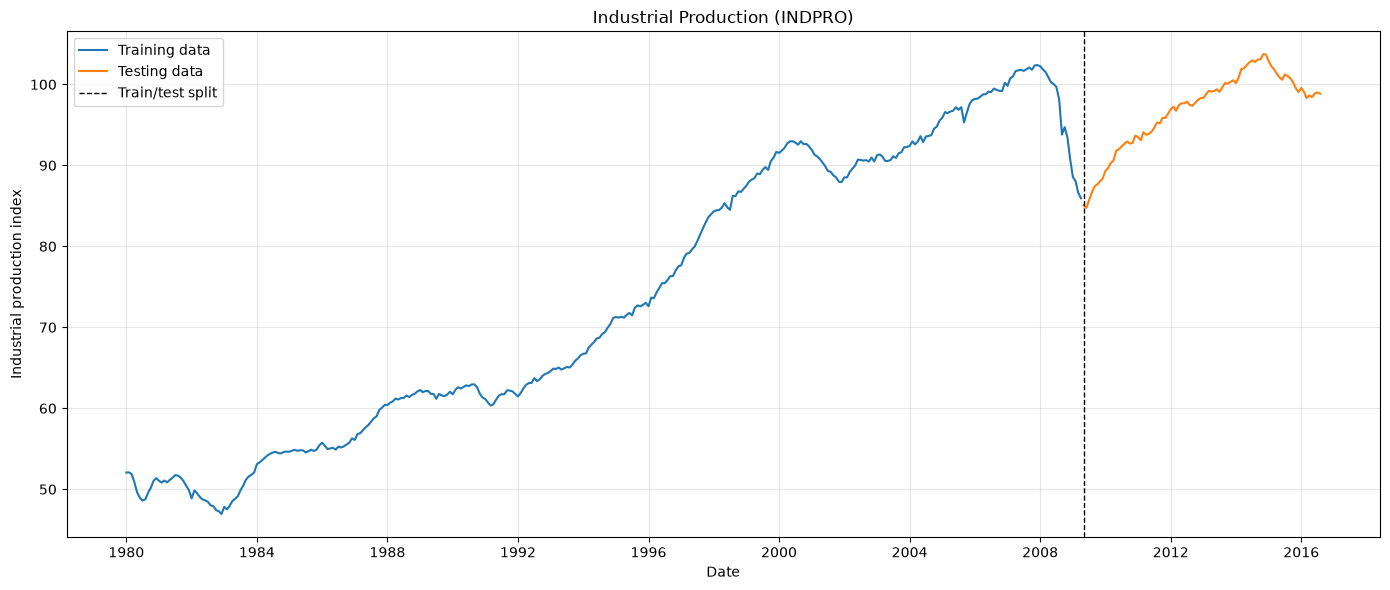

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import matplotlib.pyplot as plt
import pandas as pd

# Load the monthly industrial production dataset.
data_path = Path("data") / "INDPRO.csv"
data = pd.read_csv(data_path, parse_dates=["observation_date"])
data = data.sort_values("observation_date").set_index("observation_date")

# Split chronologically: the first 80% is used for training and the final 20% for testing.
split_index = int(len(data) * 0.8)
train = data.iloc[:split_index].copy()
test = data.iloc[split_index:].copy()

print(f"Total observations: {len(data)}")
print(f"Training observations: {len(train)} ({len(train) / len(data):.1%})")
print(f"Testing observations: {len(test)} ({len(test) / len(data):.1%})")
print(f"Training period: {train.index.min().date()} to {train.index.max().date()}")
print(f"Testing period: {test.index.min().date()} to {test.index.max().date()}")

# Plot the full series and distinguish the training and testing periods.
plt.figure(figsize=(14, 6))
plt.plot(train.index, train["INDPRO"], label="Training data")
plt.plot(test.index, test["INDPRO"], label="Testing data")
plt.axvline(test.index[0], color="black", linestyle="--", linewidth=1, label="Train/test split")
plt.title("Industrial Production (INDPRO)")
plt.xlabel("Date")
plt.ylabel("Industrial production index")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Validácia výberu parametrov ARIMA modelu

Správny model spoznáme tak, že: 

1. ACF a PACF lagy rezíduí ležia kompletne v pásme šumu bez vyčnievajúcich lagov (teda v reziduách sa nechádza žiadna signifikantná autokorelácia

2. Ljung-Boxov test potvrdzuje biely šum
    -   Nulová hypotéza: Reziduá sú nezávislé a identicky rozdelené
    -   $p > 0.05 \implies$ žiadna zvyšková autokorelácia

3. AIC/BIC dosahuje čo najnižšiu hodnotu - rovnováha medzi presnosťou na dátach a zložitosťou modelu
    -   AIC prioritou je presnosť predikcií
    -   BIC prioritou je hľadanie jednoduchého a robustného modelu
    
4. Reziduá sú približne normálne rozdelené (histogram/Q-Q graf).


c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                 INDPRO   No. Observations:                  352
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -276.883
Date:                Tue, 13 Oct 2026   AIC                            557.766
Time:                        15:54:52   BIC                            565.487
Sample:                    01-01-1980   HQIC                           560.839
                         - 04-01-2009                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2007      0.025      8.122      0.000       0.152       0.249
sigma2         0.2836      0.009     30.858      0.000       0.266       0.302
Ljung-Box (L1) (Q):                   0.29   Jarque-

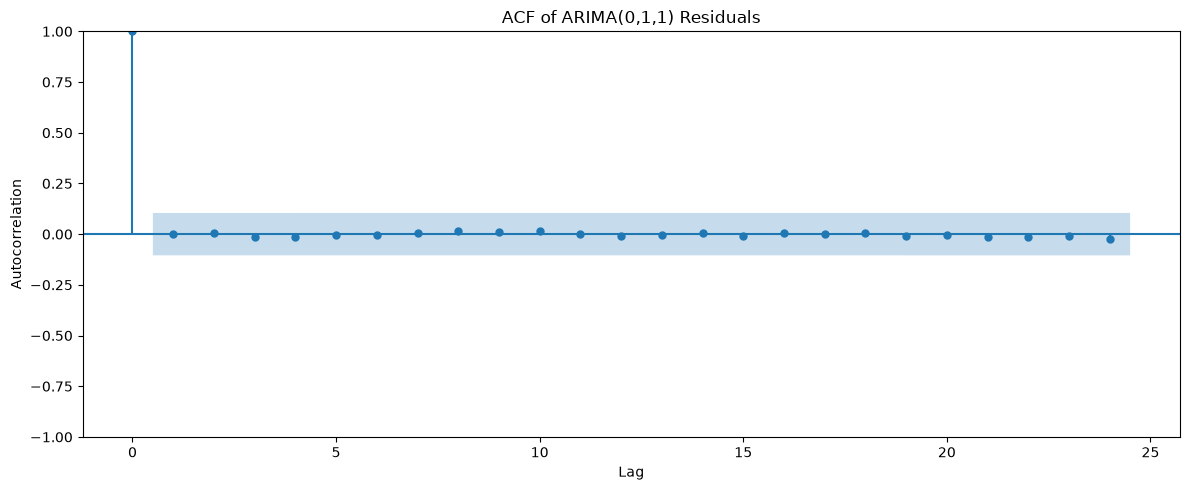

Ljung-Box test results:
     lb_stat  lb_pvalue
3   0.058844   0.996270
6   0.131416   0.999955
9   0.264279   0.999998
12  0.361797   1.000000


In [2]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Fit an ARIMA(0,1,1) model to the training observations.
arima_model = ARIMA(train["INDPRO"], order=(0, 1, 1))
arima_result = arima_model.fit()
residuals = arima_result.resid.dropna()

print(arima_result.summary())

# Plot the autocorrelation of the model residuals.
fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(residuals, lags=24, ax=ax)
ax.set_title("ACF of ARIMA(0,1,1) Residuals")
ax.set_xlabel("Lag")
ax.set_ylabel("Autocorrelation")
fig.tight_layout()
plt.show()

# Test whether the residuals are independent at the requested lags.
ljung_box_results = acorr_ljungbox(
    residuals,
    lags=[3, 6, 9, 12],
    return_df=True,
)
print("Ljung-Box test results:")
print(ljung_box_results)

# 3. Hľadanie vhodnejšieho modelu
| Typ procesu | ACF graf | PACF graf | Voľba rádu |
| :--- | :--- | :--- | :--- |
| **AR($p$)** | Postupný pokles (tail off) | **Prudký pád po lagu $p$** (cut off) | $p$ = počet lagov pred pádom, $q = 0$ |
| **MA($q$)** | **Prudký pád po lagu $q$** (cut off) | Postupný pokles (tail off) | $p = 0$, $q$ = počet lagov pred pádom |
| **ARMA($p,q$)** | Postupný pokles | Postupný pokles | Kandidáti: kombinácie $p, q$ overené cez AIC/BIC |
| **Biely šum** | Všetky lagy v pásme šumu | Všetky lagy v pásme šumu | $p = 0, q = 0$ |

Original series: ADF statistic=-1.6513, p-value=0.456338
Differenced series (d=1): ADF statistic=-4.5151, p-value=0.000185
ARIMA candidates sorted by AIC:
 p  d  q        AIC        BIC
 1  1  2 489.548660 504.991805
 1  1  3 490.219824 509.523755
 3  1  1 490.539687 509.843618
 2  1  2 490.564846 509.868777
 2  1  1 490.786247 506.229392
 3  1  2 491.845232 515.009949
 2  1  3 492.218245 515.382963
 3  1  3 492.709301 519.734805
 1  1  1 493.976408 505.558767
 3  1  0 501.633067 517.076211
 2  1  0 519.766187 531.348545
 0  1  3 527.702217 543.145362
 0  1  2 543.734025 555.316383
 1  1  0 546.704592 554.426164
 0  1  1 557.765915 565.487487
 0  1  0 576.413616 580.274402
Selected order by AIC: (1, 1, 2)
AIC=489.549, BIC=504.992
Ljung-Box test for selected model:
     lb_stat  lb_pvalue
3   0.127865   0.988296
6   0.259670   0.999669
9   0.598579   0.999934
12  0.750936   0.999997
auto_arima order: (1, 1, 2)
auto_arima AIC: 489.549
Grid-search order: (1, 1, 2)


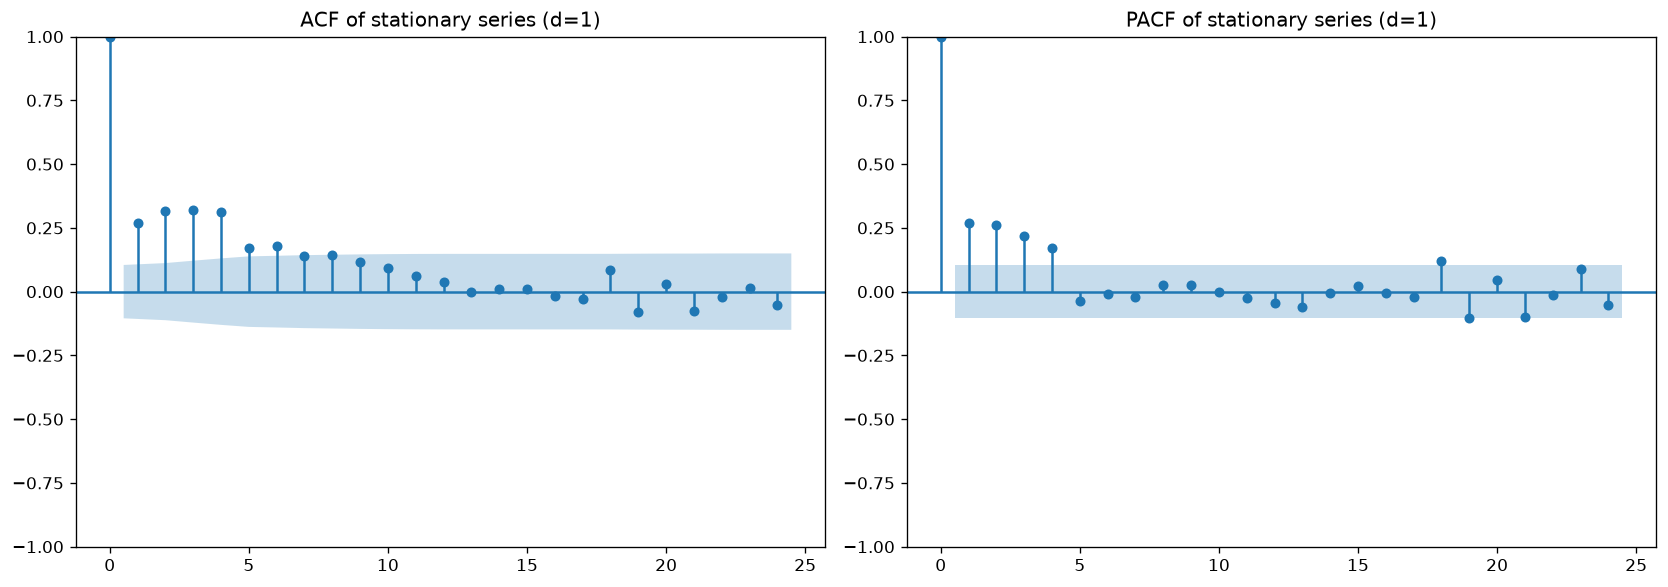

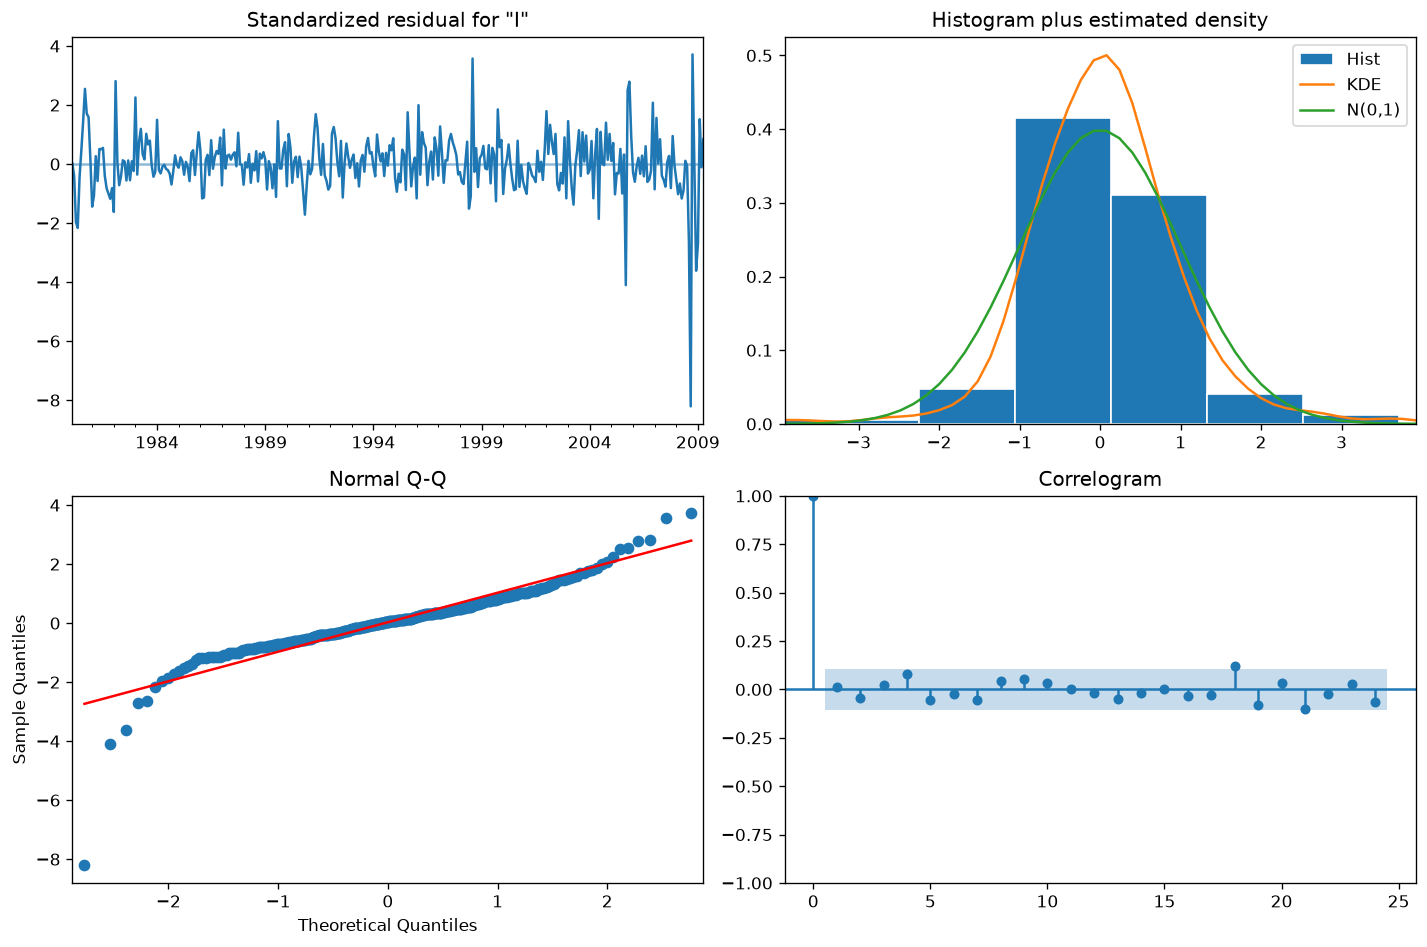

In [3]:
from itertools import product

import numpy as np
from pmdarima import auto_arima

series = train["INDPRO"].dropna()

def adf_summary(values, label):
    result = adfuller(values, autolag="AIC")
    print(f"{label}: ADF statistic={result[0]:.4f}, p-value={result[1]:.6f}")
    return result[1]

differenced_series = series.copy()
d = 0
p_value = adf_summary(differenced_series, "Original series")
while p_value > 0.05 and d < 2:
    d += 1
    differenced_series = series.diff(d).dropna()
    p_value = adf_summary(differenced_series, f"Differenced series (d={d})")

if p_value > 0.05:
    raise ValueError("The series is still non-stationary after two differences.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(differenced_series, lags=24, ax=axes[0])
plot_pacf(differenced_series, lags=24, ax=axes[1], method="ywm")
axes[0].set_title(f"ACF of stationary series (d={d})")
axes[1].set_title(f"PACF of stationary series (d={d})")
fig.tight_layout()
plt.show()

candidate_results = []
for p, q in product(range(4), repeat=2):
    try:
        candidate = ARIMA(series, order=(p, d, q)).fit()
        candidate_results.append({"p": p, "d": d, "q": q, "AIC": candidate.aic, "BIC": candidate.bic})
    except (ValueError, np.linalg.LinAlgError):
        continue

grid_results = pd.DataFrame(candidate_results).sort_values("AIC").reset_index(drop=True)
print("ARIMA candidates sorted by AIC:")
print(grid_results.to_string(index=False))

best_order = tuple(grid_results.loc[0, ["p", "d", "q"]].astype(int))
best_result = ARIMA(series, order=best_order).fit()
print(f"Selected order by AIC: {best_order}")
print(f"AIC={best_result.aic:.3f}, BIC={best_result.bic:.3f}")

best_result.plot_diagnostics(figsize=(12, 8), lags=24)
plt.tight_layout()
plt.show()

selected_residuals = best_result.resid.dropna()
selected_ljung_box = acorr_ljungbox(selected_residuals, lags=[3, 6, 9, 12], return_df=True)
print("Ljung-Box test for selected model:")
print(selected_ljung_box)

auto_model = auto_arima(
    series, d=d, start_p=0, start_q=0, max_p=3, max_q=3,
    seasonal=False, stepwise=True, suppress_warnings=True, error_action="ignore"
)
print(f"auto_arima order: {auto_model.order}")
print(f"auto_arima AIC: {auto_model.aic():.3f}")
print(f"Grid-search order: {best_order}")

## 4. Evaluácia predikčnej schopnosti modelu pomocou Rolling-Origin

Rolling-Origin testuje ARIMA model opakovaným posúvaním (sliding) alebo rozširovaním (expanding) tréningového okna. 

<div align="center">
<img src="images/fixed-vs-rolling-window-time-series.png" alt="ACF vs PACF perspektíva" width="480"/>
</div>


c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\L

Rolling-origin forecast order: (1, 1, 2)
                            MAE      RMSE
ARIMA                  0.353763  0.473749
Naive                  0.405332  0.485901
Exponential Smoothing  0.395321  0.529170


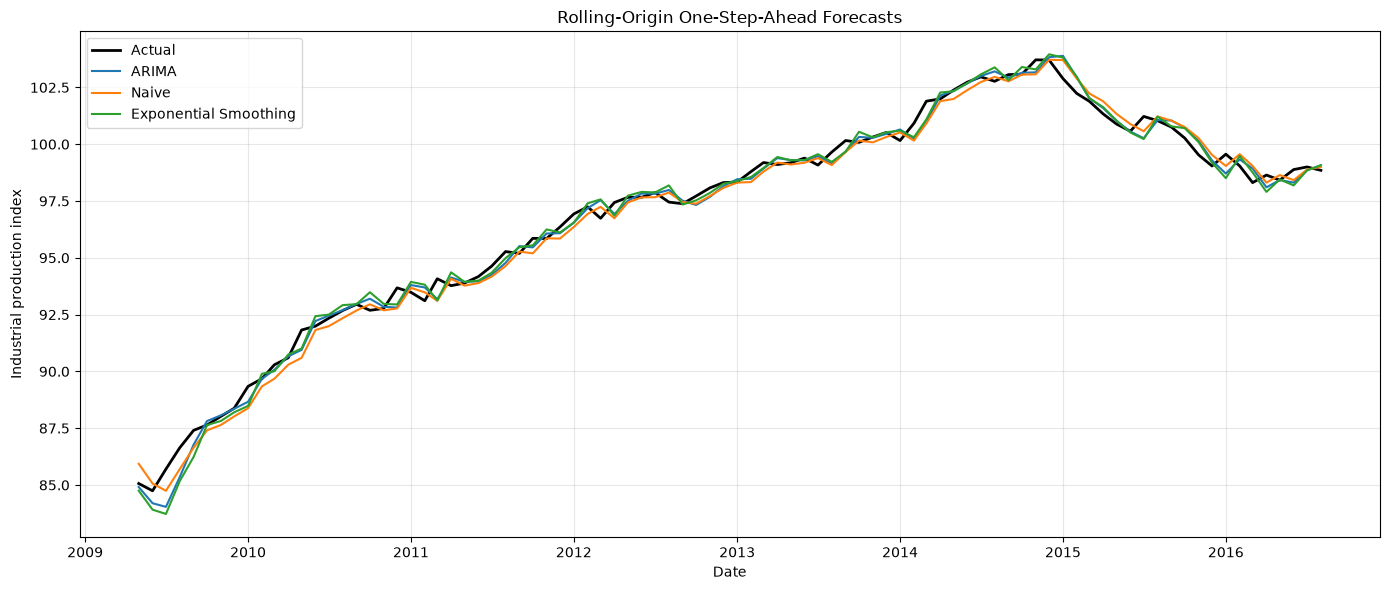

In [5]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

forecast_order = best_order if "best_order" in globals() else (0, 1, 1)
history = train["INDPRO"].copy()
actual = test["INDPRO"].copy()
arima_forecasts, naive_forecasts, smoothing_forecasts = [], [], []

# Expanding-window, one-step-ahead rolling-origin evaluation.
for timestamp, observed_value in actual.items():
    arima_fit = ARIMA(history, order=forecast_order).fit()
    arima_forecasts.append(float(arima_fit.forecast(1).iloc[0]))
    naive_forecasts.append(float(history.iloc[-1]))
    smoothing_fit = ExponentialSmoothing(
        history, trend="add", seasonal="add", seasonal_periods=12,
        initialization_method="estimated"
    ).fit(optimized=True)
    smoothing_forecasts.append(float(smoothing_fit.forecast(1).iloc[0]))
    history.loc[timestamp] = observed_value

forecasts = pd.DataFrame({
    "Actual": actual,
    "ARIMA": arima_forecasts,
    "Naive": naive_forecasts,
    "Exponential Smoothing": smoothing_forecasts,
}, index=actual.index)

errors = forecasts.drop(columns="Actual").subtract(forecasts["Actual"], axis=0)
metrics = pd.DataFrame({
    "MAE": errors.abs().mean(),
    "RMSE": (errors.pow(2).mean()) ** 0.5,
}).sort_values("RMSE")

print(f"Rolling-origin forecast order: {forecast_order}")
print(metrics)

plt.figure(figsize=(14, 6))
plt.plot(forecasts.index, forecasts["Actual"], color="black", linewidth=2, label="Actual")
for model in ["ARIMA", "Naive", "Exponential Smoothing"]:
    plt.plot(forecasts.index, forecasts[model], label=model)
plt.title("Rolling-Origin One-Step-Ahead Forecasts")
plt.xlabel("Date")
plt.ylabel("Industrial production index")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### BONUS — 2B Predikcia dennej výroby elektriny

Spracujte dvojročné dáta nemeckej elektrickej siete z priečinka `data/` a vytvorte model na predikciu dennej celkovej výroby elektriny pre jún–december 2025. Porovnajte presnosť modelu SARIMA s modelom SARIMAX rozšíreným o 2 vhodné exogénne premenné. Odôvodnite svoj výber exogénnych premenných.

## Postup

Cieľom je predikovať **dennú celkovú výrobu** verejnej siete v Nemecku od 1. júna do 31. decembra 2025.

Vstupom sú 15-minútové údaje Energy-Charts za roky 2024 a 2025 (výkon v MW). Denná výroba je energia v GWh:

- sčítajú sa len výrobné zdroje (voda, biomasa, uhlie, plyn, vietor, slnko a ďalšie),
- každý štvrťhodinový výkon sa vynásobí 0,25 h,
- súčet sa zarovná na kalendárny deň v časovom pásme Europe/Berlin, takže dni so zmenou času majú 23 alebo 25 hodín.

**Spotreba prečerpávacích elektrární do výroby nevstupuje** — v dátach je záporná a ide o odber, nie o výrobu.

Tréning je 1. 1. 2024 – 31. 5. 2025. Test je celý horizont zadania, 1. 6. 2025 – 31. 12. 2025. Predikcia je jedna viackroková predpoveď z konca mája, nie jednokrokový nowcast.

Sezónna perióda je **7 dní**. Ročná perióda 365 by po sezónnej diferencii nechala z 517 tréningových dní príliš krátky rad.

## Prečo práve tieto dve exogénne premenné

SARIMAX má dostať veličiny, ktoré výrobu ovplyvňujú a **nie sú jej zložkou**. Inak by model čítal cieľ z jeho vlastných súčastí.

1. **Denné zaťaženie (Load, GWh).** Je to fyzikálny dopyt, ktorý musí domáca výroba spolu s dovozom pokryť. Na tréningu so výrobou koreluje približne 0,75. Nie je to výrobný zdroj, takže nejde o únik cieľa.

2. **Priemerná day-ahead cena DE-LU (EUR/MWh).** Sama so výrobou takmer nekoreluje, lebo cenu súčasne zdvíha vysoký dopyt. Po odstránení lineárneho vplyvu zaťaženia je parciálna korelácia výrazne záporná: pri rovnakom zaťažení vysoká výroba z vetra a slnka tlačí cenu nadol a prebytok ide na export, kým vysoká cena sprevádza dovoz a nižšiu domácu výrobu. Cena preto nesie inú informáciu ako zaťaženie.

Ostatné stĺpce sa nehodia. Vietor, slnko, uhlie, plyn a podiel obnoviteľných zdrojov sú súčasť alebo funkcia cieľa. Spotreba prečerpávania s dennou výrobou na tréningu prakticky nekoreluje a je skôr dôsledkom prebytku.

Rád oboch modelov je rovnaký, vybraný podľa AIC/BIC len na tréningu. Rozdiel v presnosti tak patrí exogénnym premenným.

**Obmedzenie.** SARIMAX na budúce dni potrebuje budúce zaťaženie a cenu. V teste používame ich skutočné hodnoty, čo je štandardné meranie prínosu exogénnych premenných. V prevádzke by zaťaženie prišlo z prognózy dopytu a day-ahead cena je známa len deň dopredu, nie na pol roka vopred.


Quarter-hour observations: 70,176
Duplicate timestamps: 0
Daily observations: 731 (2024-01-01 to 2025-12-31)
Missing daily values: 0
Intervals per day (92 = spring DST, 100 = autumn DST):
n_intervals
92       2
96     727
100      2
Train: 517 days (2024-01-01 to 2025-05-31)
Test:  214 days (2025-06-01 to 2025-12-31)

Correlation with daily generation (training sample):
generation_gwh            1.000
load_gwh                  0.755
price_eur_mwh             0.017
pumped_consumption_gwh    0.012
renewable_share_pct       0.091
corr(load, price) = 0.494
partial corr(generation, price | load) = -0.625
Highest training day-ahead price: 395.3 EUR/MWh on 2024-12-12
ADF level: statistic=-2.520, p-value=0.1107
ADF first difference: statistic=-8.100, p-value=1.305e-12
ADF weekly difference: statistic=-6.752, p-value=2.941e-09


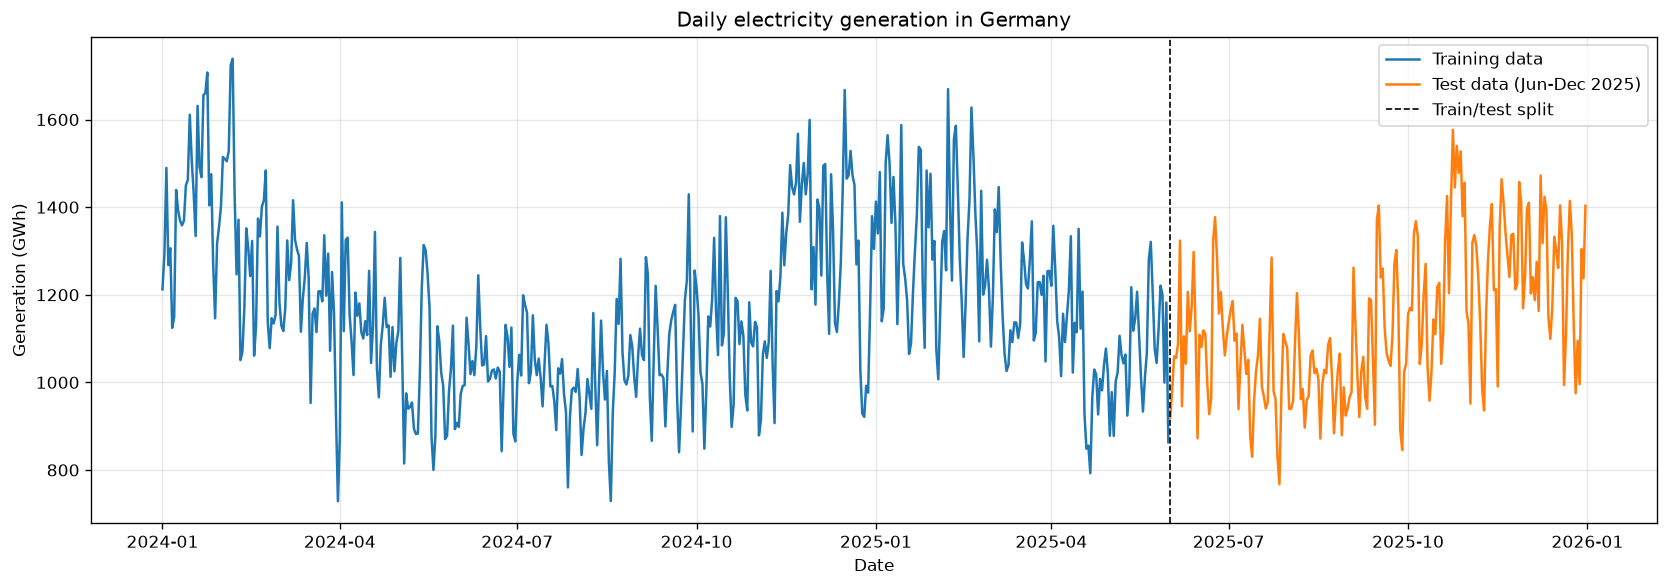

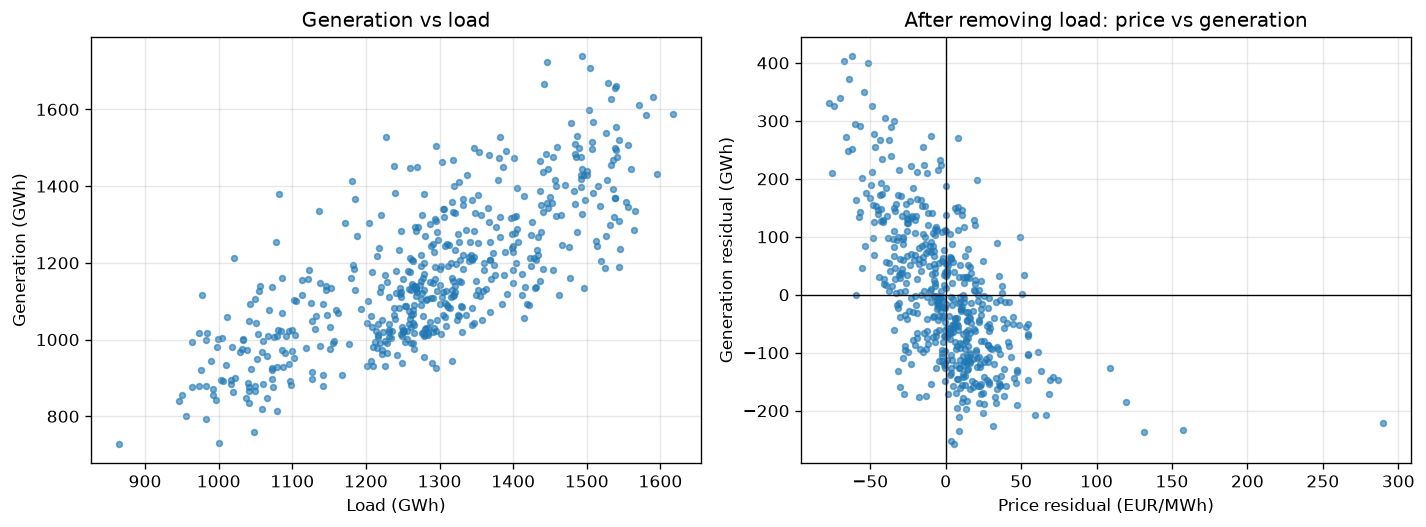

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller

DATA_DIR = Path("data")
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

GENERATION_COLUMNS = [
    "Hydro Run-of-River",
    "Biomass",
    "Fossil brown coal / lignite",
    "Fossil hard coal",
    "Fossil oil",
    "Fossil coal-derived gas",
    "Fossil gas",
    "Geothermal",
    "Hydro water reservoir",
    "Hydro pumped storage",
    "Others",
    "Waste",
    "Wind offshore",
    "Wind onshore",
    "Solar",
]
INTERVAL_HOURS = 0.25


def load_energy_year(year):
    path = DATA_DIR / f"energy-charts_Public_net_electricity_generation_in_Germany_in_{year}.csv"
    first_line = path.read_text(encoding="utf-8-sig").splitlines()[0]
    # The 2024 file starts with a note about the day-ahead auction; both files have a units row.
    skiprows = [0, 2] if not first_line.startswith("Date") else [1]
    frame = pd.read_csv(path, skiprows=skiprows, low_memory=False)
    frame.columns = frame.columns.astype(str).str.strip()
    frame = frame.rename(columns={frame.columns[0]: "timestamp"})
    frame["timestamp"] = pd.to_datetime(frame["timestamp"], utc=True).dt.tz_convert("Europe/Berlin")
    frame = frame.dropna(subset=["timestamp"]).set_index("timestamp").sort_index()
    numeric_columns = GENERATION_COLUMNS + [
        "Hydro pumped storage consumption",
        "Load",
        "Day Ahead Auction (DE-LU)",
        "Renewable share of generation",
    ]
    for column in numeric_columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame


def to_daily(frame):
    local_day = frame.index.tz_localize(None).floor("D")
    generation_mwh = frame[GENERATION_COLUMNS].sum(axis=1, min_count=len(GENERATION_COLUMNS))
    daily = pd.DataFrame(
        {
            "generation_gwh": generation_mwh.groupby(local_day).sum() * INTERVAL_HOURS / 1000,
            "load_gwh": frame["Load"].groupby(local_day).sum() * INTERVAL_HOURS / 1000,
            "price_eur_mwh": frame["Day Ahead Auction (DE-LU)"].groupby(local_day).mean(),
            "pumped_consumption_gwh": (
                frame["Hydro pumped storage consumption"].groupby(local_day).sum() * INTERVAL_HOURS / 1000
            ),
            "renewable_share_pct": frame["Renewable share of generation"].groupby(local_day).mean(),
            "n_intervals": frame["Load"].groupby(local_day).size(),
        }
    )
    daily.index.name = "date"
    return daily.sort_index()


energy = pd.concat([load_energy_year(2024), load_energy_year(2025)]).sort_index()
daily = to_daily(energy).asfreq("D")

print(f"Quarter-hour observations: {len(energy):,}")
print(f"Duplicate timestamps: {int(energy.index.duplicated().sum())}")
print(f"Daily observations: {len(daily)} ({daily.index.min().date()} to {daily.index.max().date()})")
print(f"Missing daily values: {int(daily.isna().any(axis=1).sum())}")
print("Intervals per day (92 = spring DST, 100 = autumn DST):")
print(daily["n_intervals"].value_counts().sort_index().to_string())

train_end = pd.Timestamp("2025-05-31")
test_start = pd.Timestamp("2025-06-01")
train = daily.loc[:train_end].copy()
test = daily.loc[test_start:].copy()
print(f"Train: {len(train)} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test:  {len(test)} days ({test.index.min().date()} to {test.index.max().date()})")

relation_columns = [
    "generation_gwh",
    "load_gwh",
    "price_eur_mwh",
    "pumped_consumption_gwh",
    "renewable_share_pct",
]
correlations = train[relation_columns].corr()["generation_gwh"].rename("corr_with_generation")
print("\nCorrelation with daily generation (training sample):")
print(correlations.round(3).to_string())

gen_coef = np.polyfit(train["load_gwh"], train["generation_gwh"], 1)
price_coef = np.polyfit(train["load_gwh"], train["price_eur_mwh"], 1)
generation_resid = train["generation_gwh"] - np.polyval(gen_coef, train["load_gwh"])
price_resid = train["price_eur_mwh"] - np.polyval(price_coef, train["load_gwh"])
partial_corr = np.corrcoef(generation_resid, price_resid)[0, 1]
print(f"corr(load, price) = {train['load_gwh'].corr(train['price_eur_mwh']):.3f}")
print(f"partial corr(generation, price | load) = {partial_corr:.3f}")

peak_price_day = train["price_eur_mwh"].idxmax()
print(
    f"Highest training day-ahead price: {train.loc[peak_price_day, 'price_eur_mwh']:.1f} EUR/MWh "
    f"on {peak_price_day.date()}"
)

adf_level = adfuller(train["generation_gwh"], autolag="AIC", result_object=False)
adf_diff = adfuller(train["generation_gwh"].diff().dropna(), autolag="AIC", result_object=False)
adf_seasonal = adfuller(train["generation_gwh"].diff(7).dropna(), autolag="AIC", result_object=False)
print(f"ADF level: statistic={adf_level[0]:.3f}, p-value={adf_level[1]:.4f}")
print(f"ADF first difference: statistic={adf_diff[0]:.3f}, p-value={adf_diff[1]:.4g}")
print(f"ADF weekly difference: statistic={adf_seasonal[0]:.3f}, p-value={adf_seasonal[1]:.4g}")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["generation_gwh"], label="Training data")
ax.plot(test.index, test["generation_gwh"], label="Test data (Jun-Dec 2025)")
ax.axvline(test.index[0], color="black", linestyle="--", linewidth=1, label="Train/test split")
ax.set_title("Daily electricity generation in Germany")
ax.set_xlabel("Date")
ax.set_ylabel("Generation (GWh)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "bonus_generation_split.png", dpi=120)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(train["load_gwh"], train["generation_gwh"], s=12, alpha=0.6)
axes[0].set_title("Generation vs load")
axes[0].set_xlabel("Load (GWh)")
axes[0].set_ylabel("Generation (GWh)")
axes[0].grid(True, alpha=0.3)
axes[1].scatter(price_resid, generation_resid, s=12, alpha=0.6)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("After removing load: price vs generation")
axes[1].set_xlabel("Price residual (EUR/MWh)")
axes[1].set_ylabel("Generation residual (GWh)")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "bonus_exog_relationship.png", dpi=120)
plt.show()


Best SARIMA candidates by AIC:
 p  d  q  P  D  Q    AIC    BIC
 1  1  1  0  1  1 6276.7 6293.6
 1  1  1  1  1  1 6278.7 6299.9
 1  1  2  1  1  1 6279.3 6304.7
 2  1  1  1  1  1 6279.5 6304.9
 2  1  2  0  1  1 6279.9 6305.3
 2  1  2  1  1  1 6282.0 6311.6
 0  1  2  1  1  1 6295.6 6316.8
 0  1  2  0  1  1 6296.4 6313.4

Selected order: SARIMA(1, 1, 1)x(0, 1, 1, 7)
                                     SARIMAX Results                                     
Dep. Variable:                    generation_gwh   No. Observations:                  517
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 7)   Log Likelihood               -3134.357
Date:                           Sun, 18 Oct 2026   AIC                           6276.713
Time:                                   21:55:00   BIC                           6293.643
Sample:                               01-01-2024   HQIC                          6283.351
                                    - 05-31-2025                                         
Covar

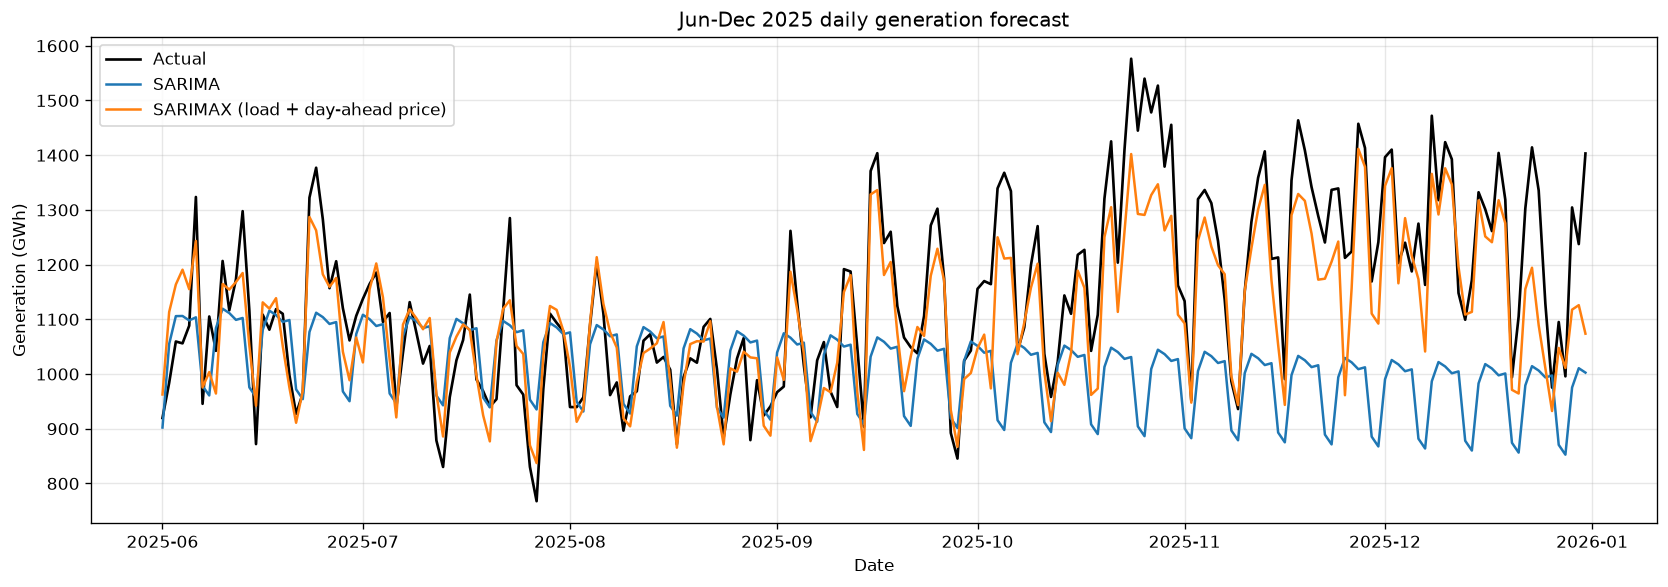

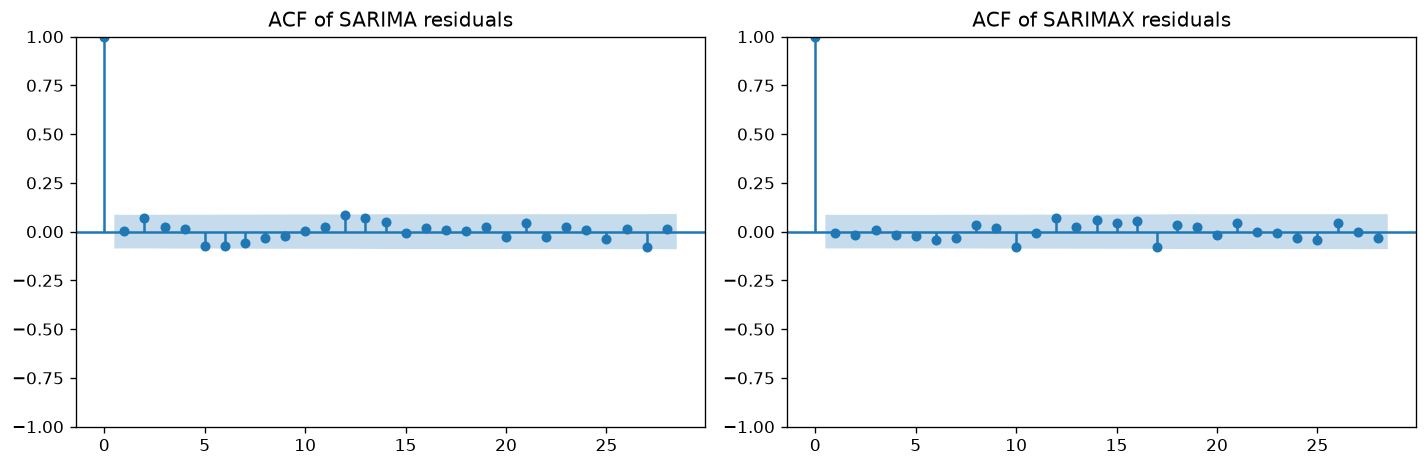

In [7]:
import warnings
from itertools import product

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX

y_train = train["generation_gwh"]
y_test = test["generation_gwh"]
exog_columns = ["load_gwh", "price_eur_mwh"]
exog_train = train[exog_columns].rename(columns={
    "load_gwh": "Load (GWh)",
    "price_eur_mwh": "Day-ahead price",
})
exog_test = test[exog_columns].rename(columns={
    "load_gwh": "Load (GWh)",
    "price_eur_mwh": "Day-ahead price",
})

# d=1 follows from the ADF test. Search the short-run and weekly seasonal orders by AIC.
candidate_results = []
for p, q, P, D, Q in product(range(3), range(3), range(2), range(2), range(2)):
    order = (p, 1, q)
    seasonal_order = (P, D, Q, 7)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            candidate = SARIMAX(
                y_train,
                order=order,
                seasonal_order=seasonal_order,
            ).fit(disp=False, maxiter=150)
        candidate_results.append({
            "p": p,
            "d": 1,
            "q": q,
            "P": P,
            "D": D,
            "Q": Q,
            "AIC": candidate.aic,
            "BIC": candidate.bic,
        })
    except Exception:
        continue

grid_results = pd.DataFrame(candidate_results).sort_values(["AIC", "BIC"]).reset_index(drop=True)
print("Best SARIMA candidates by AIC:")
print(grid_results.head(8).round(1).to_string(index=False))

best = grid_results.iloc[0]
order = (int(best["p"]), int(best["d"]), int(best["q"]))
seasonal_order = (int(best["P"]), int(best["D"]), int(best["Q"]), 7)
print(f"\nSelected order: SARIMA{order}x{seasonal_order}")

sarima = SARIMAX(y_train, order=order, seasonal_order=seasonal_order).fit(disp=False)
sarimax = SARIMAX(
    y_train, exog=exog_train, order=order, seasonal_order=seasonal_order
).fit(disp=False)
print(sarima.summary())
print(sarimax.summary())

sarima_forecast = pd.Series(sarima.get_forecast(steps=len(test)).predicted_mean.to_numpy(), index=test.index)
sarimax_forecast = pd.Series(
    sarimax.get_forecast(steps=len(test), exog=exog_test).predicted_mean.to_numpy(),
    index=test.index,
)
seasonal_naive = pd.Series(np.resize(y_train.iloc[-7:].to_numpy(), len(test)), index=test.index)


def forecast_metrics(predicted, name):
    error = predicted.to_numpy() - y_test.to_numpy()
    return {
        "model": name,
        "MAE_GWh": np.mean(np.abs(error)),
        "RMSE_GWh": np.sqrt(np.mean(error ** 2)),
        "MAPE_%": np.mean(np.abs(error / y_test.to_numpy())) * 100,
    }


metrics = pd.DataFrame([
    forecast_metrics(seasonal_naive, "Seasonal naive (lag 7)"),
    forecast_metrics(sarima_forecast, "SARIMA"),
    forecast_metrics(sarimax_forecast, "SARIMAX"),
])
print("\nJun-Dec 2025 forecast accuracy:")
print(metrics.round(2).to_string(index=False))
print(f"SARIMA  AIC={sarima.aic:.1f}  BIC={sarima.bic:.1f}")
print(f"SARIMAX AIC={sarimax.aic:.1f}  BIC={sarimax.bic:.1f}")

for name, result in [("SARIMA", sarima), ("SARIMAX", sarimax)]:
    ljung_box = acorr_ljungbox(result.resid.dropna(), lags=[7, 14, 28], return_df=True)
    print(f"\nLjung-Box test, {name} residuals:")
    print(ljung_box.round(4).to_string())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test, color="black", linewidth=1.6, label="Actual")
ax.plot(sarima_forecast.index, sarima_forecast, label="SARIMA")
ax.plot(sarimax_forecast.index, sarimax_forecast, label="SARIMAX (load + day-ahead price)")
ax.set_title("Jun-Dec 2025 daily generation forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Generation (GWh)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "bonus_forecast_comparison.png", dpi=120)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(sarima.resid.dropna(), lags=28, ax=axes[0])
plot_acf(sarimax.resid.dropna(), lags=28, ax=axes[1])
axes[0].set_title("ACF of SARIMA residuals")
axes[1].set_title("ACF of SARIMAX residuals")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "bonus_residual_acf.png", dpi=120)
plt.show()


## Výsledok

Mriežka na tréningu vyberá podľa AIC aj BIC rád **SARIMA(1, 1, 1)×(0, 1, 1)₇**. SARIMAX používa ten istý rád, takže rozdiel v presnosti patrí zaťaženiu a day-ahead cene.

Viackroková predikcia na 214 dní (1. 6. – 31. 12. 2025):

| Model | MAE (GWh) | RMSE (GWh) | MAPE |
| :--- | ---: | ---: | ---: |
| Sezónne naivná (posledný týždeň) | 151,6 | 185,6 | 13,0 % |
| SARIMA | 162,8 | 215,2 | 13,2 % |
| SARIMAX | 65,1 | 84,0 | 5,5 % |

SARIMAX zníži MAE zhruba na dve pätiny chyby SARIMA a MAPE z 13,2 % na 5,5 %. AIC klesá z 6276,7 na 5807,7 a BIC z 6293,6 na 5833,1, takže dva parametre navyše sú na tréningu opodstatnené.

Koeficient zaťaženia je **1,09** (p < 0,001): gigawatthodina dopytu navyše ide spolu s približne 1,09 GWh výroby. Koeficient day-ahead ceny je **−2,81 GWh na každé euro za MWh** (p < 0,001). Záporné znamienko sedí s parciálnou koreláciou −0,63. Pri rovnakom zaťažení nižšia cena sprevádza vyššiu výrobu, typicky prebytok vetra a slnka a export, a vyššia cena sprevádza nižšiu domácu výrobu.

SARIMA na polročnom horizonte drží týždenné kmity okolo úrovne z konca mája a minie jesenný nárast výroby, preto na tomto horizonte neprekoná ani opakovanie posledného týždňa. SARIMAX sleduje sezónnu úroveň aj väčšinu denných výkyvov. Najvyššie októbrové špičky stále mierne podhodnocuje.

Ljung-Boxov test na lagoch 7, 14 a 28 neodmieta nezávislosť rezíduí ani pri jednom modeli (všetky p > 0,18). Rezíduá SARIMAX majú ťažšie chvosty ako normálne rozdelenie; bodové porovnanie MAE a RMSE to nemení.

Porovnanie počíta so známym budúcim zaťažením a známou day-ahead cenou. V prevádzke by zaťaženie prišlo z prognózy dopytu a day-ahead cena je známa len deň dopredu, nie na celý jún–december.
